# 27 · The SSIM loss and the JND loss together

Notebook 26 trained the two best bodies on the JND loss instead of the SSIM loss, and found that the two fail in
different ways. The SSIM loss (`metrics.ssim_l1_loss`, 84% luma SSIM, 16% RGB L1) places edges well and keeps the
brightness, but leaves a faint grid of the upscaler's pixels (a step across two LR pixels' outputs is 1.21-1.29 times
a step inside one; in the truth 1.04) and, on the fast q24, less of the fine detail. The JND loss takes most of that
grid away (1.16-1.17) and keeps more detail, and one viewer preferred it in 11 of 20 blind pairs against 5, but it
lets what it cannot see drift: edges a little less exact, and the picture half a level brighter than the SSIM loss's.

This notebook trains the sum, the SSIM loss + λ × the JND loss, so that the first holds edges and brightness while the
second takes out the grid:

- **The JND term** is `PerceptualJNDLoss` at the spec's defaults (45 px a degree, 64 px tiles, masking exponent 0.7,
  tiles pooled at β = 4, d / (d + 1) a picture): notebook 26's first round, which trained better models than the
  settings in `helpers/jnd_settings.json`.
- **λ = 0.1, 0.3 and 1.** Section 2 measures how hard each loss pulls on the weights: on a trained model the two pull
  equally at λ ≈ 0.35-0.39, so the three give the JND term about a quarter of, the same as, and three times the SSIM
  loss's pull. A run is named by its λ: **mix 0.3** is the SSIM loss + 0.3 × the JND loss.
- **The recipe** is notebooks 22's, 24's and 26's: both bodies (told 24×2, fast q24), seeds 0 and 1, notebook 21's
  pairs, Adam from 1e-3, batch 32, the rate halved after 6 epochs without improvement, from random weights; the best
  epoch is the one with the lowest mix on the validation patches.

Each mix is set against the two runs it lies between, loaded from their files: the SSIM-loss runs of notebooks 22 and
24, and the JND-loss runs of notebook 26's first round. The judges are notebook 26's: SSIM-Y, luma dB, JND and its MOS
(under `helpers/jnd_settings.json`), and the two that no loss here trains on, LPIPS and GMSD.

In [1]:
"""Settings."""

import json
import os
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from IPython.display import Image as Show, display
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Subset

os.environ["DATASETS_DIR"] = "/mnt/d/datasets"   # where the datasets are: set before helpers is imported

from helpers import degrade, judges, metrics, models, patches, sources, training
from helpers.training import DEVICE

PAIRS_DIR = sources.ROOT / "upscale" / "qp_slice_pairs"            # notebook 21
RUN_DIR = training.CHECKPOINT_DIR / "mix_runs"                     # the mixed-loss trainings, saved every epoch
SAMPLES = training.SAMPLE_DIR / "27_mix"                           # pictures, written to look at

QP_MAX = 51
CONDITIONS = ("qp", "deblocked", "intra")
BATCH_SIZE, LEARNING_RATE, MAX_EPOCHS = 32, 1e-3, 500
SEEDS = (0, 1)
LAMBDAS = {"mix 0.1": 0.1, "mix 0.3": 0.3, "mix 1": 1.0}          # mix λ: the SSIM loss + λ x the JND loss
LOSSES = ("SSIM loss", *LAMBDAS, "JND loss")                       # from no JND to only JND
# the two bodies: their arguments, and the run files of their SSIM-loss trainings (notebooks 22 and 24) and their
# JND-loss trainings (notebook 26's first round, the spec's defaults)
BODIES = {
    "told 24x2": {"arguments": dict(conditions=3, width=24, blocks=2, stem=3),
                  "ssim_runs": training.CHECKPOINT_DIR / "qp_slice_runs" / "told_QP_frame_seed{seed}.pt",
                  "jnd_runs": training.CHECKPOINT_DIR / "jnd_runs" / "_spec_defaults" / "told_24x2_seed{seed}.pt"},
    "fast q24": {"arguments": dict(width=24, stem=4, blocks=1, skip="truncated"),
                 "ssim_runs": training.CHECKPOINT_DIR / "fast_runs" / "q24_frozen_skip_seed{seed}.pt",
                 "jnd_runs": training.CHECKPOINT_DIR / "jnd_runs" / "_spec_defaults" / "fast_q24_seed{seed}.pt"},
}
# validation sources by their YouTube-8M topic: a label of the video, not of what each picture shows
SCREEN_TOPICS = {"Computer", "Font", "IPad", "IPhone", "Microsoft_Windows", "Office", "Personal_computer", "Screenshot",
                 "Text_messaging", "Web_page", "Website"}
GAME_TOPICS = {"Angry_Birds", "Counter-Strike_video_game", "Euro_Truck_Simulator_2", "Grand_Theft_Auto_V", "Minecraft",
               "RuneScape", "Sprite_computer_graphics", "Strategy_video_game", "Terraria", "Total_War_series",
               "Touhou_Project", "Video_game"}

training.seed_everything(0)
RUN_DIR.mkdir(parents=True, exist_ok=True)
SAMPLES.mkdir(parents=True, exist_ok=True)
print("perceptual repo:", judges.PERCEPTUAL_DIR)

perceptual repo: /home/henrik/projects/perceptual


## 1. Data

Notebook 21's pairs, read as notebook 26 reads them: every patch carries the slice QP / 51, the loop filter and I
frame. The validation patches are also grouped by their video's topic - screens (computers, phones, the web, office,
fonts, text), games, and the rest (camera and animation) - and by encoder.

In [2]:
manifest = training.load_manifest(PAIRS_DIR)
training.describe(manifest)
SCALE = manifest["scale"]
ENCODERS = manifest["encoders"]
trim = training.trimmer(manifest)


class WithConditions(Dataset):
    """A split's pairs as ((LR, condition (3, 1, 1)), HR), and each patch's labels and topic as arrays."""

    def __init__(self, split, augment):
        self.pairs = patches.PatchPairs(PAIRS_DIR, split, manifest, augment=augment)
        files = manifest["splits"][split]
        self.labels = {name: np.load(PAIRS_DIR / files[name]) for name in ("qp", "deblocked", "intra", "encoder")}
        values = np.stack([self.labels["qp"] / QP_MAX, self.labels["deblocked"], self.labels["intra"]], axis=1)
        self.conditions = torch.from_numpy(values.astype(np.float32))[:, :, None, None]
        self.topic = np.empty(len(self), dtype=object)
        for source in files["sources"]:
            self.topic[slice(*source["patches"])] = source["category"]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        lr, hr = self.pairs[index]
        return (lr, self.conditions[index]), hr


def loader(dataset, indices=None, train=False):
    kept = dataset if indices is None else Subset(dataset, indices)
    return DataLoader(kept, batch_size=BATCH_SIZE if train else 128, shuffle=train, drop_last=train)


train_set, val_set = WithConditions("train", augment=True), WithConditions("val", augment=False)
content = np.where(np.isin(val_set.topic, list(SCREEN_TOPICS)), "screens",
                   np.where(np.isin(val_set.topic, list(GAME_TOPICS)), "games", "camera & animation"))
intra = val_set.labels["intra"].astype(bool)
GROUPS = {"all": np.ones(len(val_set), bool),
          **{kind: content == kind for kind in ("screens", "games", "camera & animation")},
          **{f"{encoder} P": (val_set.labels["encoder"] == e) & ~intra for e, encoder in enumerate(ENCODERS)},
          "I frames": intra}
print(f"train {len(train_set)} patches, val {len(val_set)} patches")
print("val: " + ", ".join(f"{name} {mask.sum()}" for name, mask in GROUPS.items()))

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 1 frames each
train 34364 patches, val 9628 patches
val: all 9628, screens 2696, games 2908, camera & animation 4024, x264 P 4192, nvenc P 4032, I frames 1404


## 2. Models and the losses

`Told` is notebook 22's wrapper, which its run files were saved through. The JND term is `helpers/jnd_settings.json`
with masking exponent 0.7 and tiles pooled at β = 4 put back, which makes it the spec's defaults: the loss notebook
26's first round trained on. Its masking is held constant under the gradient, so a model cannot hide an error behind
texture it adds.

In [3]:
class Told(nn.Module):
    """Notebook 22's wrapper: a `ToldLuma` given all three conditions."""

    def __init__(self, model):
        super().__init__()
        self.model, self.parts = model, list(range(len(CONDITIONS)))

    def forward(self, x, condition):
        return self.model(x, condition[:, self.parts])


def build(body):
    if body == "told 24x2":
        return Told(models.ToldLuma(scale=SCALE, **BODIES[body]["arguments"]))
    return models.FastLuma(**BODIES[body]["arguments"])


class Bicubic(nn.Module):
    def forward(self, x, condition=None):
        return models.bicubic(x, SCALE)


jnd_term = judges.jnd_loss(masking_exponent=0.7, beta_tiles=4)   # the spec's defaults: d / (d + 1), the batch's mean


def loss_of(loss):
    """The training loss of a row of LOSSES."""
    if loss == "SSIM loss":
        return metrics.ssim_l1_loss
    if loss == "JND loss":
        return jnd_term
    weight = LAMBDAS[loss]
    return lambda prediction, target: metrics.ssim_l1_loss(prediction, target) + weight * jnd_term(prediction, target)

### How hard each loss pulls

The two losses are on different scales, and what a loss adds to a training step is its gradient, not its value.
Below is the length of each loss's gradient on the model's weights, the mean over 16 training batches, for a model
before training and for the SSIM-loss run of seed 0. Their ratio is the λ at which the two pull equally.

In [4]:
def grad_length(model, loss_fn, batches):
    """The length of a loss's gradient on the model's weights, the mean over `batches`."""
    model.train()
    lengths = []
    for (lr, condition), hr in batches:
        model.zero_grad(set_to_none=True)
        loss_fn(trim(model(lr, condition)), hr).backward()
        lengths.append(torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters() if p.grad is not None)).item())
    return float(np.mean(lengths))


torch.manual_seed(0)
batches = []
for (lr, condition), hr in loader(train_set, train=True):
    batches.append(((lr.to(DEVICE), condition.to(DEVICE)), hr.to(DEVICE)))
    if len(batches) == 16:
        break
print("gradient length on the weights, the mean of 16 training batches")
for body in BODIES:
    for state in ("untrained", "SSIM loss, seed 0"):
        torch.manual_seed(0)
        model = build(body).to(DEVICE)
        if state != "untrained":
            path = Path(str(BODIES[body]["ssim_runs"]).format(seed=0))
            model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True)["model"])
        ssim_pull, jnd_pull = grad_length(model, metrics.ssim_l1_loss, batches), grad_length(model, jnd_term, batches)
        print(f"  {body:<10} {state:<18} SSIM loss {ssim_pull:.3f}   JND loss {jnd_pull:.3f}   "
              f"equal at λ = {ssim_pull / jnd_pull:.2f}")

gradient length on the weights, the mean of 16 training batches
  told 24x2  untrained          SSIM loss 0.718   JND loss 0.318   equal at λ = 2.26
  told 24x2  SSIM loss, seed 0  SSIM loss 0.200   JND loss 0.517   equal at λ = 0.39
  fast q24   untrained          SSIM loss 0.184   JND loss 0.374   equal at λ = 0.49
  fast q24   SSIM loss, seed 0  SSIM loss 0.149   JND loss 0.432   equal at λ = 0.35


## 3. Train

The SSIM-loss and JND-loss runs are loaded from their files (notebooks 22 and 24, and notebook 26's first round in
`checkpoints/jnd_runs/_spec_defaults/`); the three mixed runs of each body and seed are trained from random weights
and saved every epoch in `checkpoints/mix_runs/`. A mixed run keeps the epoch with the lowest mix on the validation
patches, clamped as shown (an improvement is 1e-5, as for the JND runs). Run the cell again after an interruption and
it carries on; a finished training just loads.

In [5]:
def run_file(body, loss, seed):
    if loss == "SSIM loss":
        return Path(str(BODIES[body]["ssim_runs"]).format(seed=seed))
    if loss == "JND loss":
        return Path(str(BODIES[body]["jnd_runs"]).format(seed=seed))
    return RUN_DIR / f"{body.replace(' ', '_')}_{loss.replace(' ', '_')}_seed{seed}.pt"


def recipe(loss):
    """`training.train`'s loss and best-epoch settings for a row of LOSSES."""
    if loss == "SSIM loss":
        return dict(loss_fn=metrics.ssim_l1_loss, select="ssim")
    key, fn = ("jnd" if loss == "JND loss" else "mix"), loss_of(loss)
    return dict(loss_fn=fn, select=key, scorer=lambda prediction, target: {key: fn(prediction.clamp(0, 1), target)},
                lower_is_better=True, min_improvement=1e-5)


def train(body, loss, seed):
    torch.manual_seed(seed)
    model = build(body).to(DEVICE)
    torch.manual_seed(seed)
    settings = recipe(loss)
    history, best = training.train(model, loader(train_set, train=True), loader(val_set), trim, MAX_EPOCHS,
                                   learning_rate=LEARNING_RATE, checkpoint=run_file(body, loss, seed), verbose=0,
                                   **settings)
    print(f"{body:<10} {loss:<10} seed {seed}: best epoch {best['epoch']:3} of {len(history):3}, "
          f"{settings['select']} {best['score']:.4f}")
    return model.eval(), history

In [6]:
trained, histories = {}, {}
for seed in SEEDS:
    for body in BODIES:
        for loss in LOSSES:
            trained[body, loss, seed], histories[body, loss, seed] = train(body, loss, seed)

told 24x2  SSIM loss  seed 0: best epoch  87 of  99, ssim 0.9287
told 24x2  mix 0.1    seed 0: best epoch  71 of  89, mix 0.1351
told 24x2  mix 0.3    seed 0: best epoch  74 of  92, mix 0.2794
told 24x2  mix 1      seed 0: best epoch  83 of 101, mix 0.7846
told 24x2  JND loss   seed 0: best epoch  91 of 109, jnd 0.7209
fast q24   SSIM loss  seed 0: best epoch  92 of 104, ssim 0.9212
fast q24   mix 0.1    seed 0: best epoch 109 of 121, mix 0.1426
fast q24   mix 0.3    seed 0: best epoch 115 of 127, mix 0.2896
fast q24   mix 1      seed 0: best epoch  77 of  95, mix 0.8042
fast q24   JND loss   seed 0: best epoch 110 of 116, jnd 0.7351
told 24x2  SSIM loss  seed 1: best epoch 103 of 115, ssim 0.9289
told 24x2  mix 0.1    seed 1: best epoch  80 of  98, mix 0.1347
told 24x2  mix 0.3    seed 1: best epoch  68 of  86, mix 0.2793
told 24x2  mix 1      seed 1: best epoch  68 of  92, mix 0.7841
told 24x2  JND loss   seed 1: best epoch  59 of  77, jnd 0.7220
fast q24   SSIM loss  seed 1: best ep

## 4. Scores

Every judge on every one of the 9,628 validation patches, the halo trimmed and the picture clamped as shown:

| judge | better | trained on by |
|---|---|---|
| SSIM-Y | higher | the SSIM loss (84% of it), and the mixes through it |
| luma dB | higher | the SSIM loss's L1, in part |
| JND (d under `helpers/jnd_settings.json`, CIEDE2000 for the tile means) | lower | none exactly: the JND term is the spec's defaults |
| MOS predicted from that d (BT.500, 1-5) | higher | the same |
| LPIPS (AlexNet, v0.1) | lower | none |
| GMSD | lower | none |

A model's score is the mean of its two seeds. The networks add the same value to R, G and B, so U and V are the skip's
under every loss and are not shown.

In [7]:
judge_jnd, lpips = judges.jnd_judge(), judges.LPIPS().to(DEVICE)
JUDGES = {"ssim": ("SSIM-Y", 1), "y": ("luma dB", 1), "jnd": ("JND", -1), "mos": ("MOS", 1),
          "lpips": ("LPIPS", -1), "gmsd": ("GMSD", -1)}


@torch.no_grad()
def per_patch(model):
    """Every judge on every validation patch, as arrays."""
    model.eval()
    out = {key: [] for key in JUDGES}
    for (lr, condition), hr in loader(val_set):
        lr, condition, hr = lr.to(DEVICE), condition.to(DEVICE), hr.to(DEVICE)
        prediction = trim(model(lr, condition)).clamp(0, 1)
        each, rated = metrics.per_image(prediction, hr), judge_jnd.evaluate(prediction, hr)
        for key, value in (("ssim", each["ssim"]), ("y", each["y"]), ("jnd", rated["jnd"]), ("mos", rated["mos"]),
                           ("lpips", lpips(prediction, hr)), ("gmsd", judges.gmsd(prediction, hr))):
            out[key].append(value.float().cpu())
    return {key: torch.cat(value).numpy() for key, value in out.items()}


scores = {"bicubic": per_patch(Bicubic())}
for key, model in trained.items():
    scores[key] = per_patch(model)


def arm(body, loss, key):
    """A model's score on every patch, the mean of its seeds."""
    return np.mean([scores[body, loss, seed][key] for seed in SEEDS], axis=0)


def print_group(name):
    mask = GROUPS[name]
    print(f"{name} ({mask.sum()} patches)")
    print(f"  {'':<22}" + "".join(f"{label:>9}" for label, _ in JUDGES.values()))
    print(f"  {'bicubic':<22}" + "".join(f"{scores['bicubic'][key][mask].mean():9.4f}" for key in JUDGES))
    for body in BODIES:
        for loss in LOSSES:
            print(f"  {body + ', ' + loss:<22}" + "".join(f"{arm(body, loss, key)[mask].mean():9.4f}" for key in JUDGES))


for name in GROUPS:
    print_group(name)
    print()

print("how far apart the two seeds land, all patches")
for body in BODIES:
    for loss in LOSSES:
        gaps = [abs(scores[body, loss, 0][key].mean() - scores[body, loss, 1][key].mean()) for key in JUDGES]
        print(f"  {body + ', ' + loss:<22}" + "".join(f"{gap:9.4f}" for gap in gaps))

all (9628 patches)
                           SSIM-Y  luma dB      JND      MOS    LPIPS     GMSD
  bicubic                  0.9045  33.5533   3.6025   3.1515   0.1556   0.0712
  told 24x2, SSIM loss     0.9288  35.0809   2.9827   3.3835   0.1208   0.0567
  told 24x2, mix 0.1       0.9283  35.1821   2.9925   3.3849   0.1209   0.0568
  told 24x2, mix 0.3       0.9278  35.2357   3.0215   3.3817   0.1218   0.0568
  told 24x2, mix 1         0.9266  35.1963   3.0371   3.3797   0.1221   0.0571
  told 24x2, JND loss      0.9224  34.9657   3.0579   3.3747   0.1231   0.0587
  fast q24, SSIM loss      0.9212  34.4735   3.1749   3.3060   0.1289   0.0600
  fast q24, mix 0.1        0.9212  34.5894   3.1840   3.3119   0.1275   0.0595
  fast q24, mix 0.3        0.9208  34.6420   3.1785   3.3169   0.1280   0.0595
  fast q24, mix 1          0.9196  34.6416   3.1495   3.3260   0.1269   0.0594
  fast q24, JND loss       0.9159  34.4830   3.1517   3.3221   0.1261   0.0604

screens (2696 patches)
         

Means hide how often: the share of patches on which each run beats the SSIM-loss run of its body, by judge (each the
mean of its two seeds; a tie counts for neither), and then by LPIPS in each group of patches.

In [8]:
print(f"{'better than the SSIM loss':<34}" + "".join(f"{label:>9}" for label, _ in JUDGES.values()))
for body in BODIES:
    for loss in LOSSES[1:]:
        cells = [np.mean(sign * (arm(body, loss, key) - arm(body, "SSIM loss", key)) > 0)
                 for key, (_, sign) in JUDGES.items()]
        print(f"  {body + ', ' + loss:<32}" + "".join(f"{cell:9.0%}" for cell in cells))
print()
names = ("all", "screens", "games", "camera & animation")
print(f"{'by LPIPS, in each group':<34}" + "".join(f"{name:>20}" for name in names))
for body in BODIES:
    for loss in LOSSES[1:]:
        cells = [np.mean((arm(body, "SSIM loss", "lpips") - arm(body, loss, "lpips"))[GROUPS[name]] > 0) for name in names]
        print(f"  {body + ', ' + loss:<32}" + "".join(f"{cell:20.0%}" for cell in cells))

better than the SSIM loss            SSIM-Y  luma dB      JND      MOS    LPIPS     GMSD
  told 24x2, mix 0.1                    41%      64%      54%      54%      52%      48%
  told 24x2, mix 0.3                    35%      63%      51%      51%      44%      51%
  told 24x2, mix 1                      24%      55%      49%      49%      46%      48%
  told 24x2, JND loss                   11%      38%      47%      47%      44%      38%
  fast q24, mix 0.1                     59%      63%      53%      53%      60%      58%
  fast q24, mix 0.3                     47%      65%      57%      57%      56%      56%
  fast q24, mix 1                       35%      57%      61%      61%      59%      56%
  fast q24, JND loss                    15%      41%      57%      57%      64%      47%

by LPIPS, in each group                            all             screens               games  camera & animation
  told 24x2, mix 0.1                               52%                 53%         

## 5. Pictures

Whole frames as the client sees them, made as notebook 26 makes them: the first validation clip of five topics,
1280×720 from its centre, frame 16 (a P frame), through the host's x264 line at its default 0.46 bits a pixel (a
640×360 stream) and starved at 0.5 Mbit/s. The models run on the whole stream frame with the client's 4 px of edge
read again around it, told the frame's slice QP, loop filter and type as the client tells them.

Each grid is the 240×135 window, at 2× with no smoothing, where the SSIM-loss run and the mix shown differ most (both
bodies summed): the truth (top) and bicubic (bottom) on the left, then the told 24×2 (top) and the fast q24 (bottom)
under the SSIM loss, the mix with the better validation LPIPS of the three, and the JND loss, all at seed 0. Picking
the mix by LPIPS makes LPIPS a judge it was chosen by; GMSD and the eye are not. Every whole frame of every run is
written to `data/samples/27_mix/frames/`, with what the stream did in `frames.json`.

the mix shown: told 24x2 mix 0.1, fast q24 mix 1 (the better validation LPIPS)
each grid: truth | told 24x2, SSIM loss | told 24x2, mix 0.1 | told 24x2, JND loss  /  bicubic | fast q24, SSIM loss | fast q24, mix 1 | fast q24, JND loss
Microsoft_Windows, default (0.460 bpp): slice QP 0, window at (420, 303)


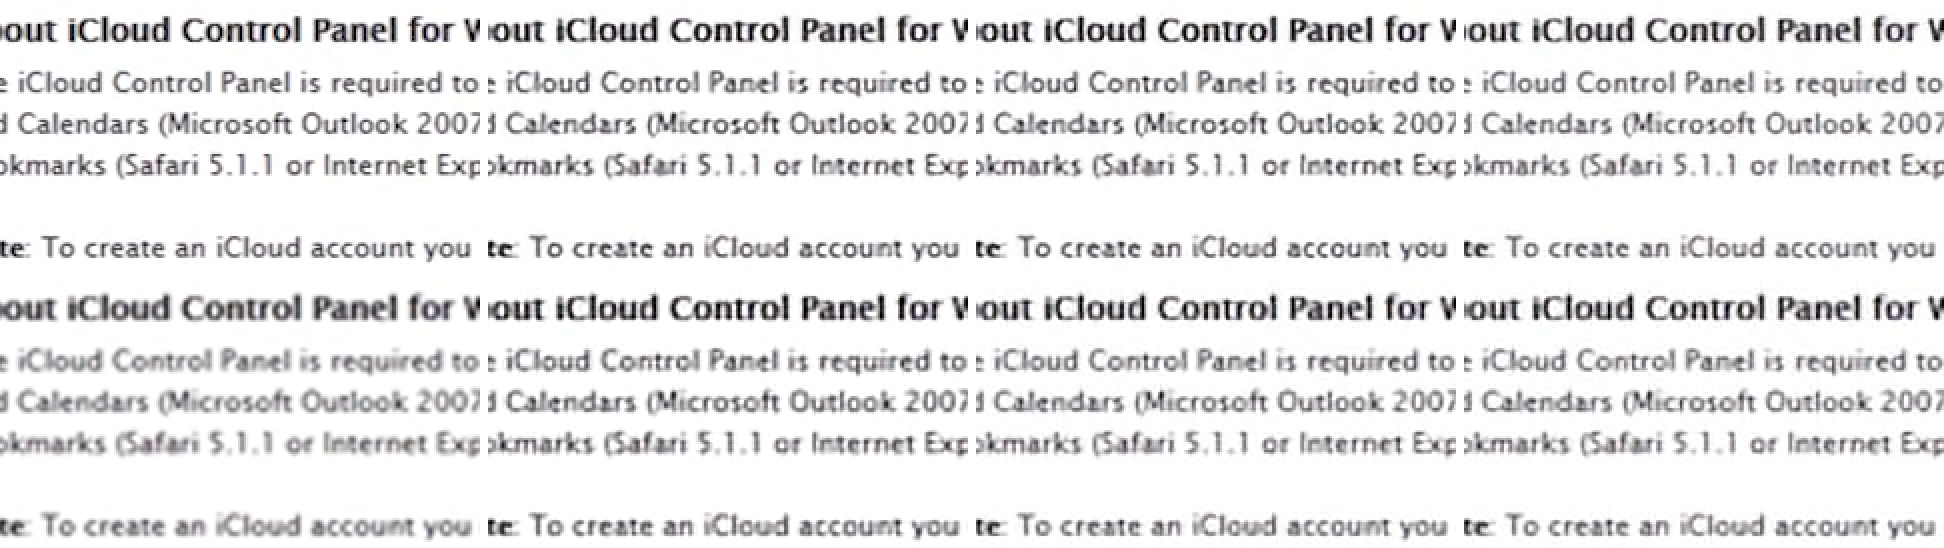

Microsoft_Windows, 0.5mbps (0.087 bpp): slice QP 17, window at (420, 303)


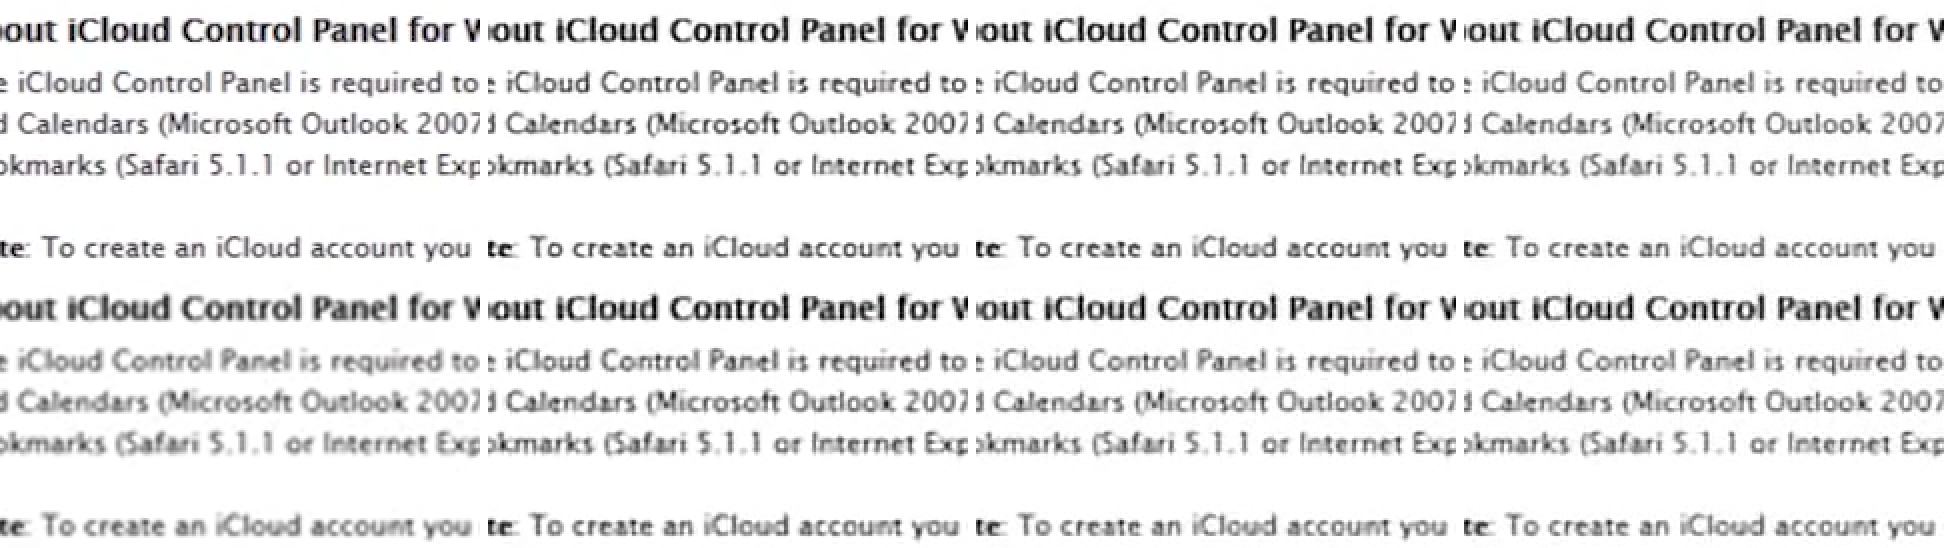

Web_page, default (0.460 bpp): slice QP 18, window at (480, 168)


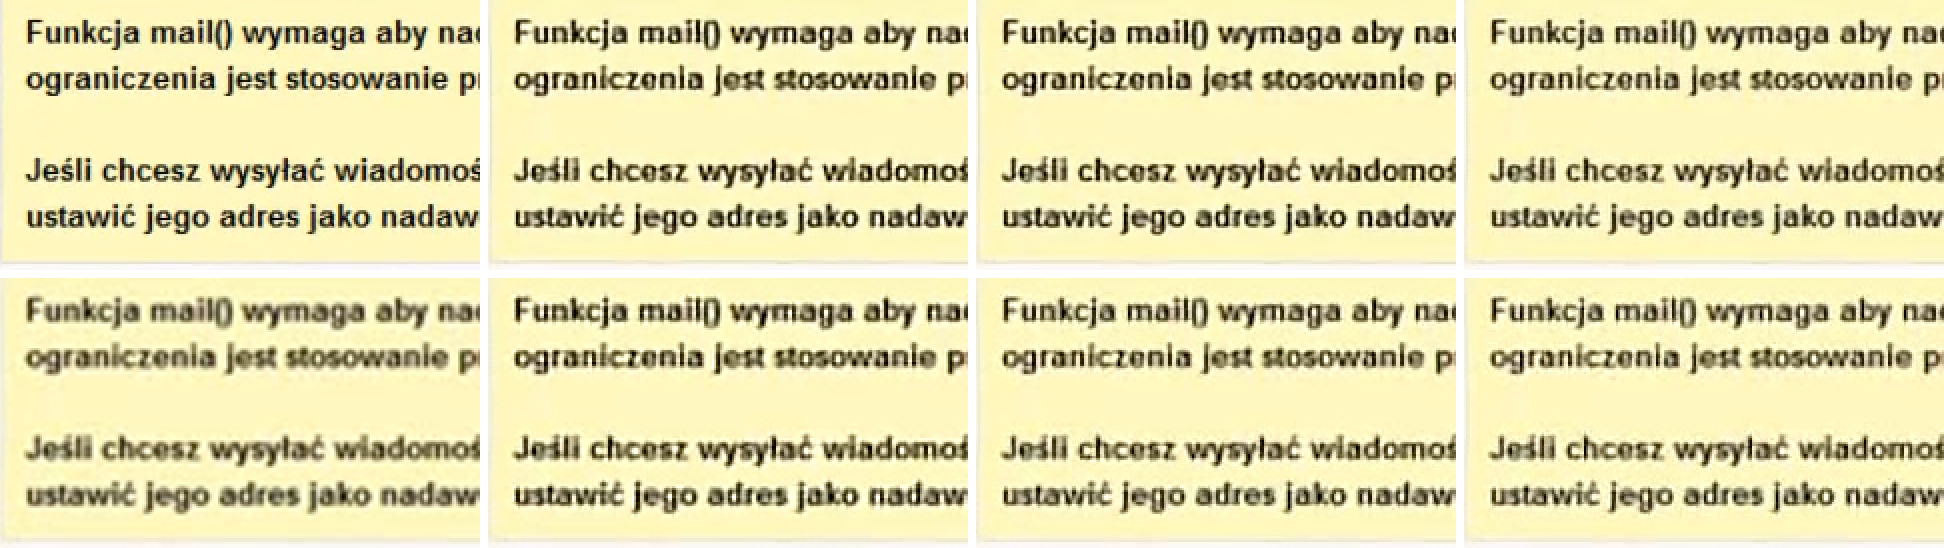

Web_page, 0.5mbps (0.072 bpp): slice QP 35, window at (480, 168)


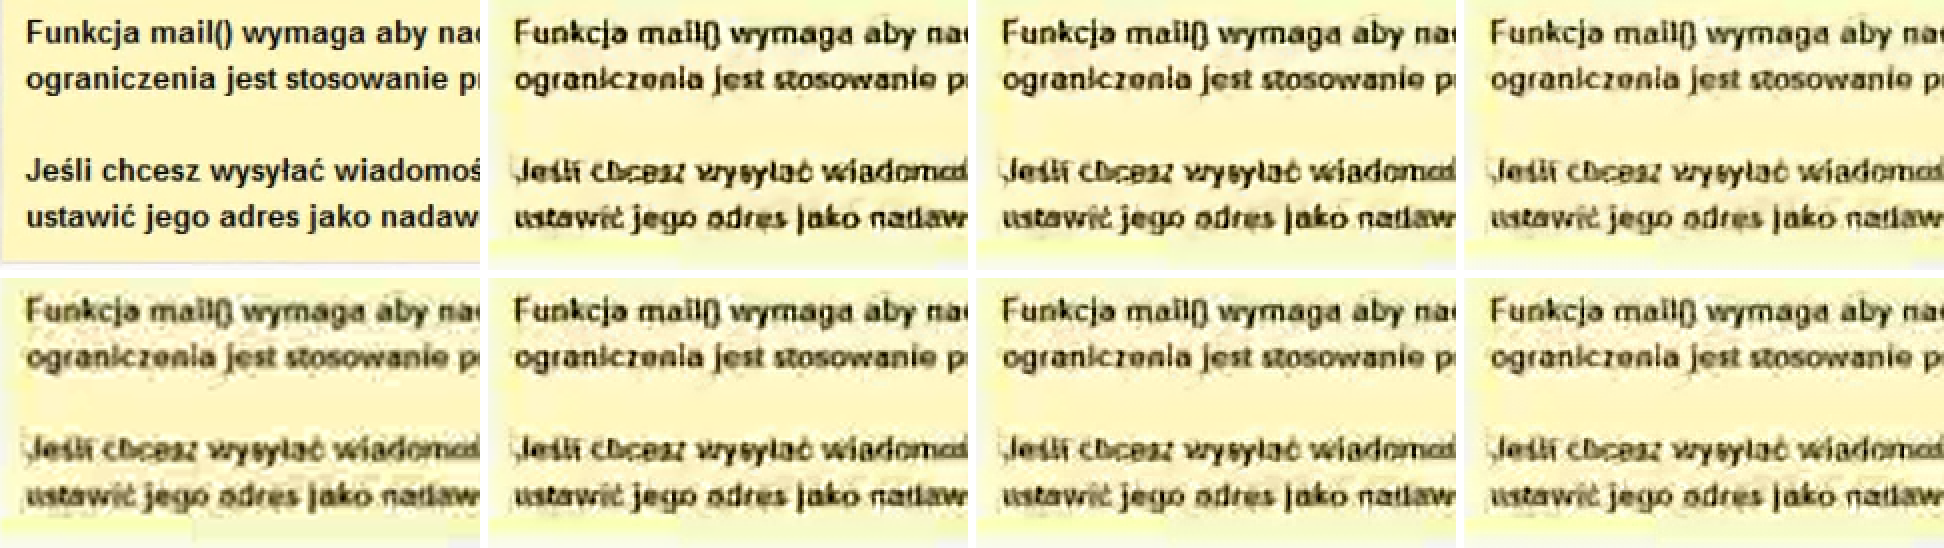

Office, default (0.460 bpp): slice QP 14, window at (780, 135)


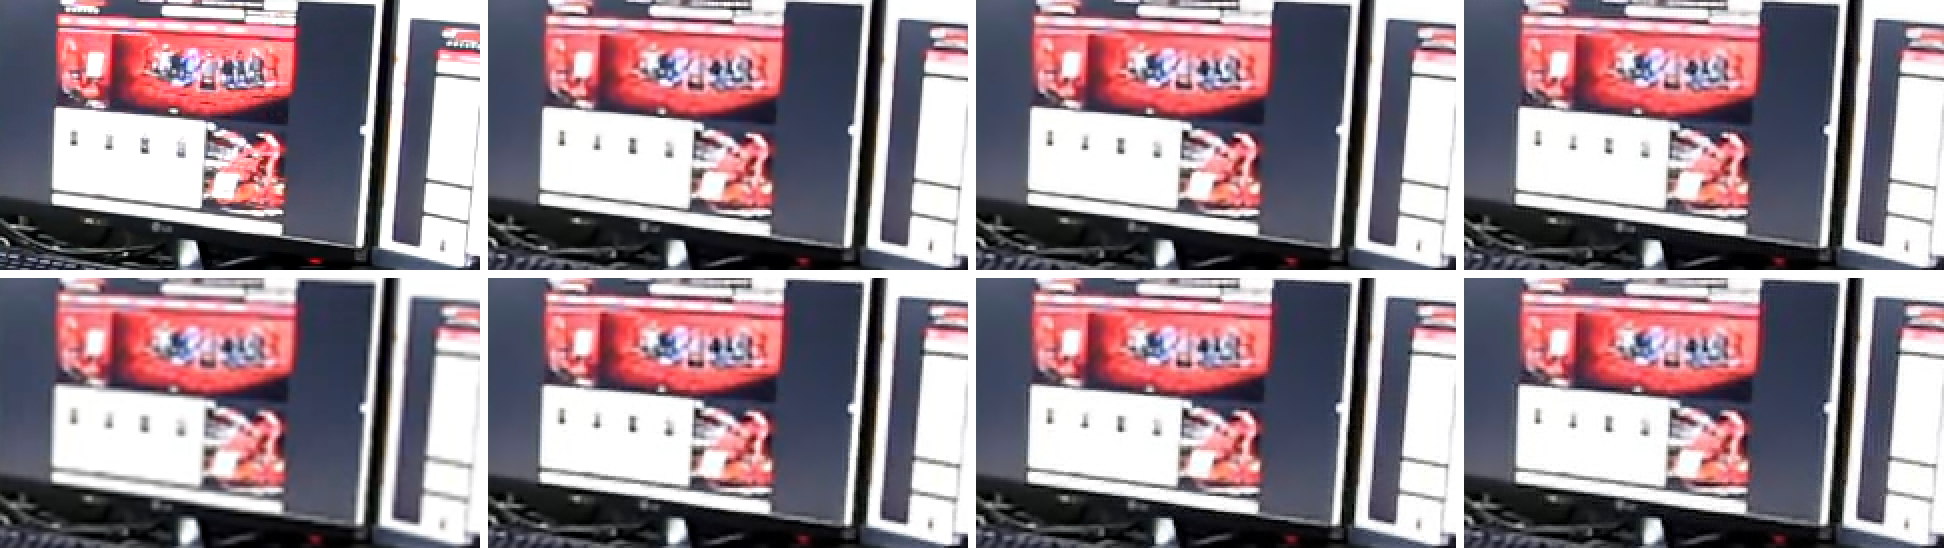

Office, 0.5mbps (0.072 bpp): slice QP 33, window at (780, 135)


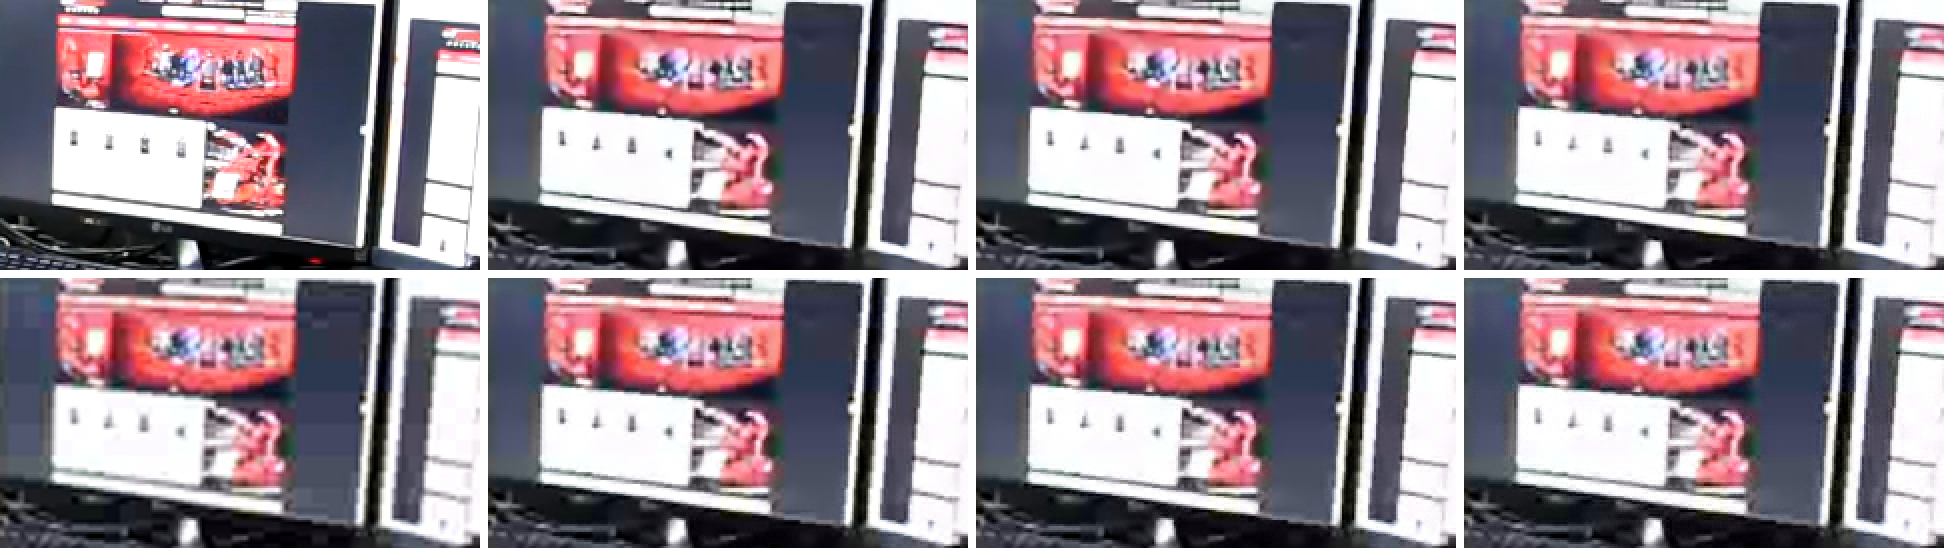

Video_game, default (0.460 bpp): slice QP 7, window at (180, 67)


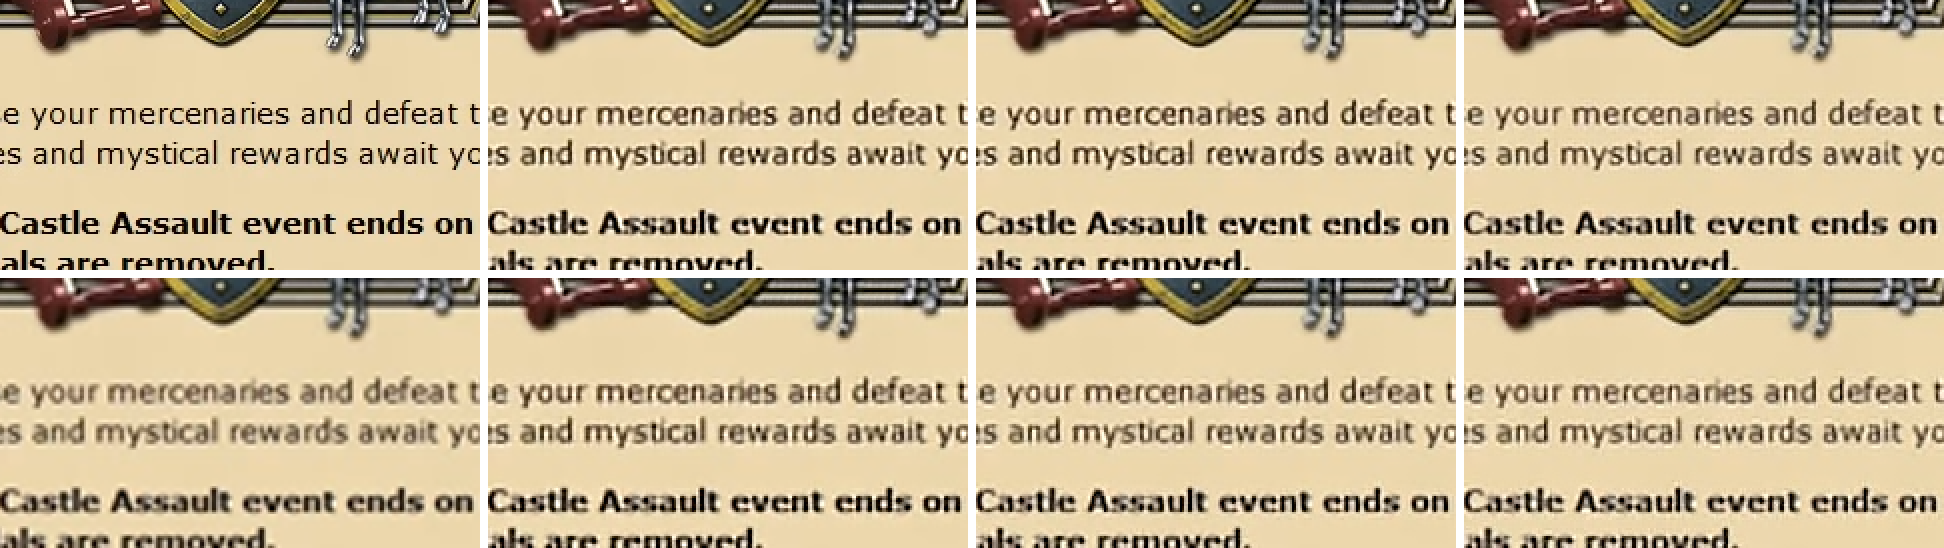

Video_game, 0.5mbps (0.087 bpp): slice QP 33, window at (180, 67)


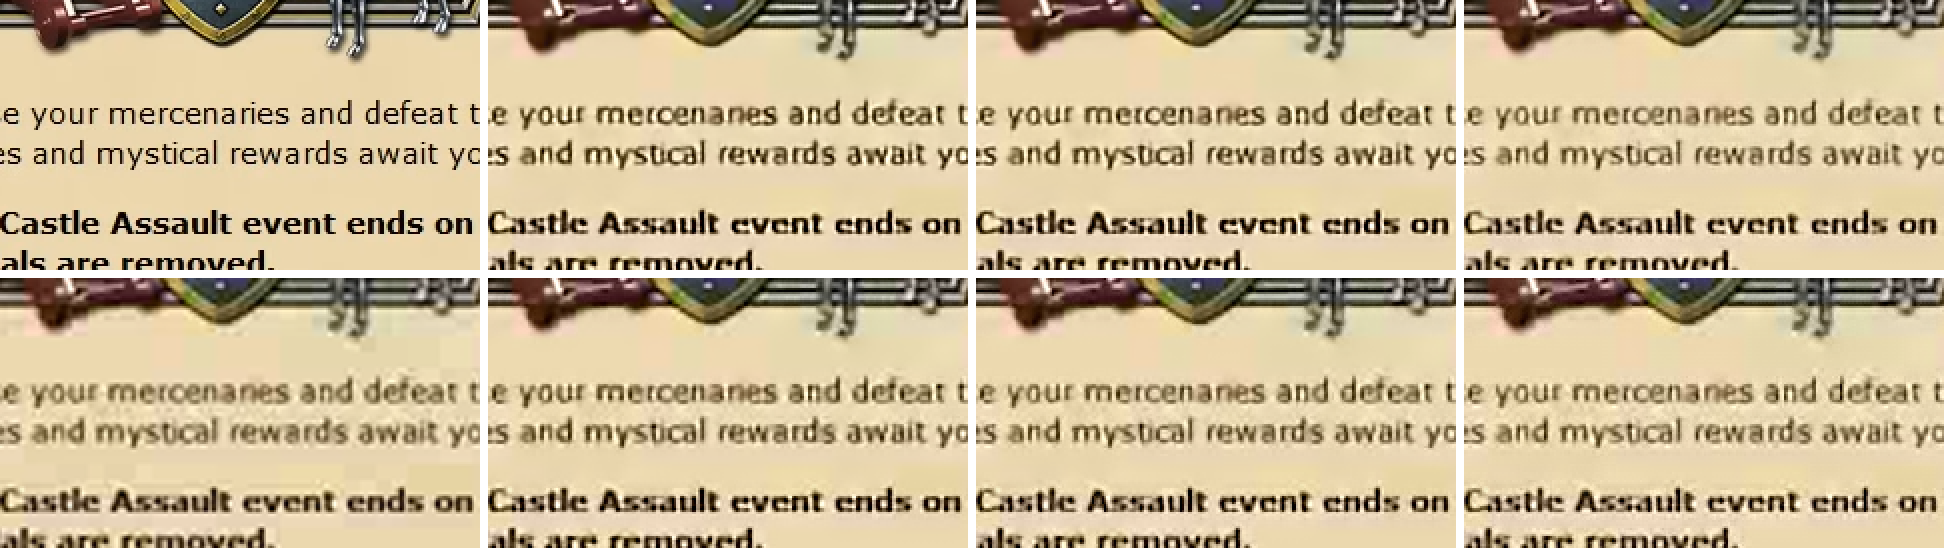

Cartoon, default (0.460 bpp): slice QP 2, window at (480, 0)


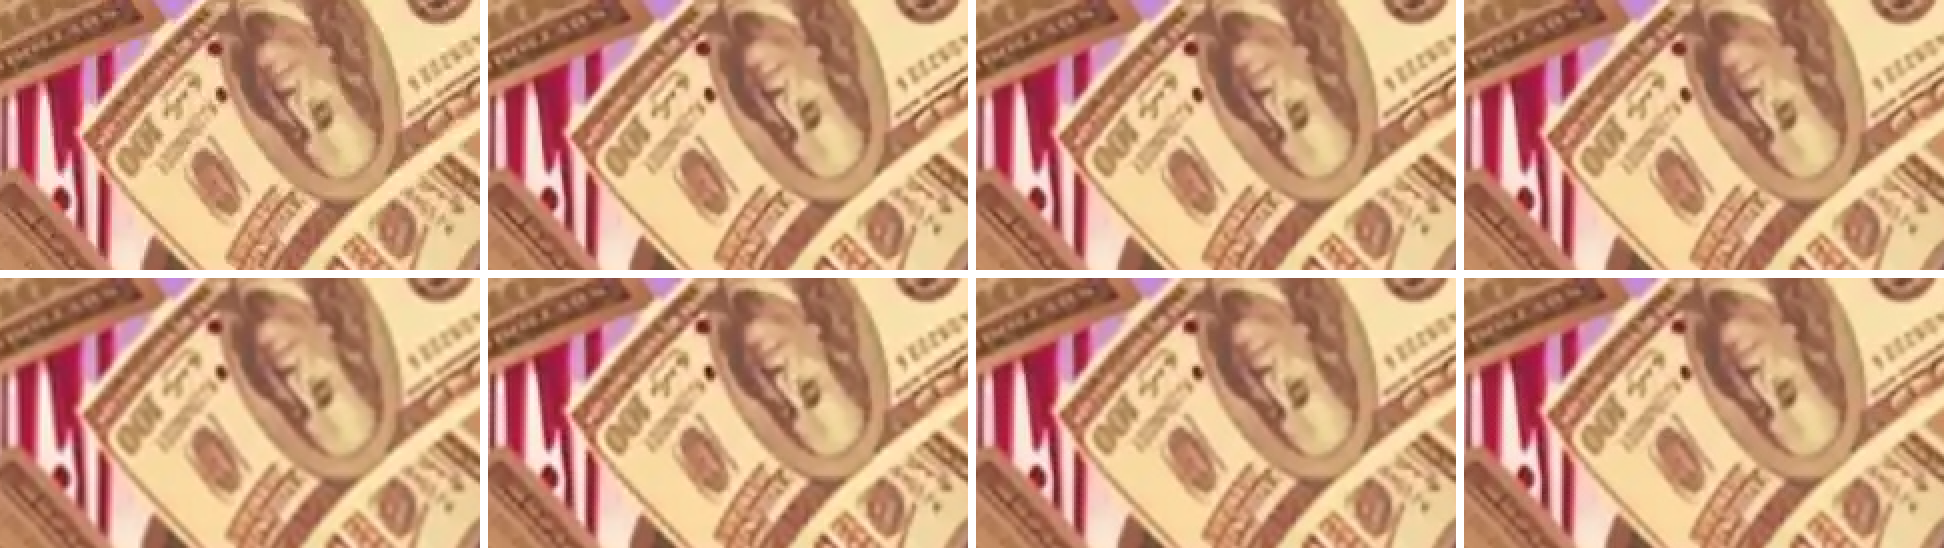

Cartoon, 0.5mbps (0.072 bpp): slice QP 27, window at (480, 0)


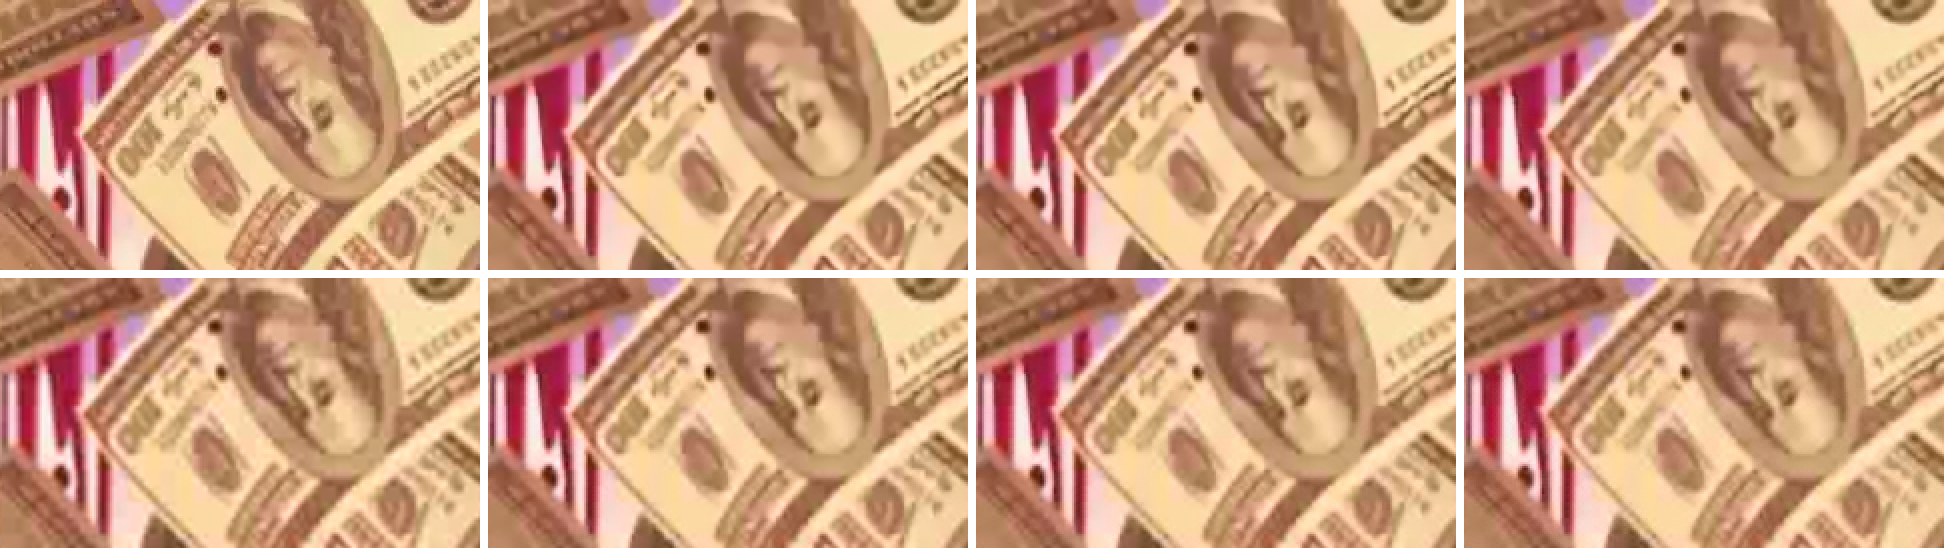

2251

In [9]:
FRAME_TOPICS = ("Microsoft_Windows", "Web_page", "Office", "Video_game", "Cartoon")
STREAMS = {"default": None, "0.5mbps": 0.5}    # the host's 0.46 bits a pixel, and a starved 0.5 Mbit/s
FRAME, CLIP_FRAMES, SIZE, WINDOW, HALO = 16, 24, (1280, 720), (135, 240), 4
SHOWN = {body: min(LAMBDAS, key=lambda loss: arm(body, loss, "lpips").mean()) for body in BODIES}
LAYOUT = [["truth", *[f"told 24x2, {loss}" for loss in ("SSIM loss", SHOWN["told 24x2"], "JND loss")]],
          ["bicubic", *[f"fast q24, {loss}" for loss in ("SSIM loss", SHOWN["fast q24"], "JND loss")]]]
FRAMES_DIR = SAMPLES / "frames"
FRAMES_DIR.mkdir(exist_ok=True)
clip_paths = {f"yt8m-videos/{path.parts[-2]}/{path.stem}": path for path in sources.files("yt8m-videos", "test")}
keys = sorted({s["key"] for s in manifest["splits"]["val"]["sources"]} & set(clip_paths))
topic_of = {s["key"]: s["category"] for s in manifest["splits"]["val"]["sources"]}


def to_uint8(x):
    return (x.clamp(0, 1) * 255).round().byte().permute(0, 2, 3, 1).cpu().numpy()


def first_clip(topic):
    """The first validation clip of a topic with CLIP_FRAMES frames of 1280x720: its key, those frames from its centre,
    and its frame rate."""
    width, height = SIZE
    for key in keys:
        if topic_of[key] != topic:
            continue
        frames, fps = sources.load_sequence(clip_paths[key])
        if len(frames) >= CLIP_FRAMES and frames.shape[1] >= height and frames.shape[2] >= width:
            top, left = (frames.shape[1] - height) // 4 * 2, (frames.shape[2] - width) // 4 * 2
            return key, frames[:CLIP_FRAMES, top:top + height, left:left + width], fps
    return None, None, None


def stream_frame(frames, fps, mbps):
    """(HR, LR, condition) of frame FRAME through the host's x264 line, at `mbps` (None: its default bits a pixel)."""
    bpp = degrade.STREAM_BPP if mbps is None else mbps * 1e6 / (SIZE[0] // SCALE * SIZE[1] // SCALE * fps)
    made = degrade.Degradation(scale=SCALE, bpp=bpp, fps=fps, filter="bicubic", deblock=False, encoder="x264")
    hr, lr, _, report = degrade.degrade(frames, made, with_frames=True)
    row = report[FRAME]
    condition = np.array([row["slice_qp"] / QP_MAX, row["deblocked"], row["type"] == "I"], np.float32)
    return hr[FRAME], lr[FRAME], condition, bpp


@torch.no_grad()
def upscale_frame(model, lr, condition):
    """A whole stream frame through a model, its edge pixels read again around it as the client does."""
    x = torch.from_numpy(np.pad(lr, ((HALO, HALO), (HALO, HALO), (0, 0)), mode="edge")).permute(2, 0, 1)[None]
    x = x.float().div(255).to(DEVICE)
    c = torch.from_numpy(condition)[None, :, None, None].to(DEVICE)
    out = model(x, c)[..., HALO * SCALE:-HALO * SCALE, HALO * SCALE:-HALO * SCALE]
    return to_uint8(out)[0]


def busiest_window(pairs):
    """The (top, left) of the WINDOW where pairs of pictures' luma differs most, summed over the pairs, on a grid of
    quarter windows."""
    luma = np.array([0.2126, 0.7152, 0.0722])
    diff = sum(np.abs(a.astype(np.float32) @ luma - b.astype(np.float32) @ luma) for a, b in pairs)
    diff = torch.from_numpy(diff.astype(np.float32))[None, None]
    sums = torch.nn.functional.avg_pool2d(diff, WINDOW, stride=(WINDOW[0] // 4, WINDOW[1] // 4))[0, 0].numpy()
    y, x = np.unravel_index(np.argmax(sums), sums.shape)
    return y * WINDOW[0] // 4, x * WINDOW[1] // 4


def grid(pictures, layout, path, zoom=2, gap=8):
    """Pictures placed as `layout` (rows of names), at `zoom` x with no smoothing, written as a PNG."""
    h, w = next(iter(pictures.values())).shape[:2]
    canvas = np.full((len(layout) * (h * zoom + gap) - gap, len(layout[0]) * (w * zoom + gap) - gap, 3), 255, np.uint8)
    for r, row in enumerate(layout):
        for c, name in enumerate(row):
            y, x = r * (h * zoom + gap), c * (w * zoom + gap)
            canvas[y:y + h * zoom, x:x + w * zoom] = pictures[name].repeat(zoom, 0).repeat(zoom, 1)
    Image.fromarray(canvas).save(path)
    return path


facts = {}
print("the mix shown: " + ", ".join(f"{body} {loss}" for body, loss in SHOWN.items()) + " (the better validation LPIPS)")
print("each grid: " + " | ".join(LAYOUT[0]) + "  /  " + " | ".join(LAYOUT[1]))
for topic in FRAME_TOPICS:
    key, frames, fps = first_clip(topic)
    if key is None:
        print(f"{topic}: no clip of 1280x720 and {CLIP_FRAMES} frames")
        continue
    for stream, mbps in STREAMS.items():
        hr, lr, condition, bpp = stream_frame(frames, fps, mbps)
        pictures = {"truth": hr, "bicubic": upscale_frame(Bicubic(), lr, condition)}
        for body in BODIES:
            for loss in LOSSES:
                pictures[f"{body}, {loss}"] = upscale_frame(trained[body, loss, 0], lr, condition)
        name = f"{topic}_{stream}"
        for label, picture in pictures.items():
            Image.fromarray(picture).save(FRAMES_DIR / f"{name}_{label.replace(', ', '_').replace(' ', '_')}.png")
        facts[name] = {"topic": topic, "clip": key, "frame": FRAME, "stream": stream, "bpp": round(bpp, 4),
                       "slice_qp": round(float(condition[0] * QP_MAX)), "deblocked": bool(condition[1]),
                       "intra": bool(condition[2]), "encoder": "x264"}
        top, left = busiest_window([(pictures[f"{body}, SSIM loss"], pictures[f"{body}, {SHOWN[body]}"]) for body in BODIES])
        window = {label: p[top:top + WINDOW[0], left:left + WINDOW[1]] for label, p in pictures.items()}
        print(f"{topic}, {stream} ({bpp:.3f} bpp): slice QP {facts[name]['slice_qp']}, window at ({left}, {top})")
        display(Show(filename=str(grid(window, LAYOUT, SAMPLES / f"frame_{name}.png"))))
(FRAMES_DIR / "frames.json").write_text(json.dumps(facts, indent=1), encoding="utf-8")

## 6. What kind of difference

Notebook 26's measures. On the validation patches, both seeds of each model: how much of the truth's fine detail it
keeps (the mean |Laplacian| of luma, over the truth's), its mean luma bias, and its luma error at the truth's strongest
edges (the top fifth of |Laplacian| in each patch) and everywhere else, in 8-bit levels. Then on the whole frames
above (seed 0), how much larger a step in luma is across a seam than anywhere else (1 is no seam): between LR pixels
(every 2 HR px), between the fast q24's 2×2 LR cells (every 4) and between the codec's macroblocks (every 16).

In [10]:
LAPLACE = torch.tensor([[0.0, 1, 0], [1, -4, 1], [0, 1, 0]], device=DEVICE)[None, None]


@torch.no_grad()
def character(model):
    """Detail kept, luma bias, and the error at edges and elsewhere, over the validation patches."""
    total = {"detail": 0.0, "truth_detail": 0.0, "bias": 0.0, "edges": 0.0, "flat": 0.0}
    for (lr, condition), hr in loader(val_set):
        lr, condition, hr = lr.to(DEVICE), condition.to(DEVICE), hr.to(DEVICE)
        truth = metrics.rgb_to_yuv(hr)[:, :1]
        picture = metrics.rgb_to_yuv(trim(model(lr, condition)).clamp(0, 1))[:, :1]
        lt, lp = (torch.nn.functional.conv2d(y, LAPLACE).abs() for y in (truth, picture))
        edges = (lt > lt.flatten(1).quantile(0.8, dim=1)[:, None, None, None]).float()
        error = (picture - truth).abs()[..., 1:-1, 1:-1]
        n = len(hr)
        total["detail"] += lp.mean().item() * n
        total["truth_detail"] += lt.mean().item() * n
        total["bias"] += 255 * (picture - truth).mean().item() * n
        total["edges"] += 255 * ((error * edges).sum() / edges.sum()).item() * n
        total["flat"] += 255 * ((error * (1 - edges)).sum() / (1 - edges).sum()).item() * n
    return {"detail": total["detail"] / total["truth_detail"], **{k: total[k] / len(val_set) for k in ("bias", "edges", "flat")}}


def seam(y, period):
    """The mean step in luma across seams every `period` px, over the mean step elsewhere, both axes."""
    out = []
    for a in (y, y.T):
        step = np.abs(np.diff(a, axis=1))
        on = np.arange(step.shape[1]) % period == period - 1
        out.append(step[:, on].mean() / step[:, ~on].mean())
    return float(np.mean(out))


luma = np.array([0.2126, 0.7152, 0.0722])
rows = {"bicubic": [Bicubic()], **{f"{body}, {loss}": [trained[body, loss, seed] for seed in SEEDS]
                                   for body in BODIES for loss in LOSSES}}
print(f"{'':<22}{'detail kept':>12}{'luma bias':>10}{'at edges':>10}{'elsewhere':>10}"
      f"{'seam 2 px':>11}{'seam 4 px':>11}{'seam 16 px':>12}")
for name in ["truth", *rows]:
    if name == "truth":
        cells = ["", "", "", ""]
    else:
        each = [character(model) for model in rows[name]]
        cells = [f"{np.mean([c[key] for c in each]):.3f}" for key in ("detail", "bias", "edges", "flat")]
    label = name.replace(", ", "_").replace(" ", "_")
    frames = [np.asarray(Image.open(FRAMES_DIR / f"{frame}_{label}.png")).astype(np.float64) @ luma for frame in facts]
    seams = [np.mean([seam(y, period) for y in frames]) for period in (2, 4, 16)]
    print(f"{name:<22}" + "".join(f"{cell:>{width}}" for cell, width in zip(cells, (12, 10, 10, 10)))
          + "".join(f"{s:{width}.3f}" for s, width in zip(seams, (11, 11, 12))))

                       detail kept luma bias  at edges elsewhere  seam 2 px  seam 4 px  seam 16 px
truth                                                                 1.043      1.087       1.076
bicubic                      0.445     0.011    10.899     2.536      1.063      1.095       1.147
told 24x2, SSIM loss         0.570    -0.155     8.807     2.318      1.207      1.161       1.140
told 24x2, mix 0.1           0.564    -0.061     8.769     2.300      1.196      1.159       1.143
told 24x2, mix 0.3           0.550     0.004     8.793     2.290      1.174      1.145       1.129
told 24x2, mix 1             0.544     0.079     8.860     2.299      1.168      1.145       1.128
told 24x2, JND loss          0.588     0.287     9.085     2.361      1.159      1.131       1.116
fast q24, SSIM loss          0.540    -0.144     9.607     2.402      1.291      1.271       1.225
fast q24, mix 0.1            0.543    -0.201     9.528     2.397      1.264      1.268       1.228
fast q24, 

## 7. What it says

Run 2026-11-19 on notebook 21's 9,628 validation patches; each model the mean of seeds 0 and 1, which land at most
0.0009 apart on LPIPS. JND and MOS are under `helpers/jnd_settings.json`; luma bias and the error at edges are in 8-bit
levels; the seam is the step across two LR pixels' outputs over the step inside one. Bold is the best of a body's five.

| | SSIM-Y | luma dB | JND | MOS | LPIPS | GMSD | luma bias | error at edges | seam every 2 px |
|---|---|---|---|---|---|---|---|---|---|
| truth | | | | | | | | | 1.043 |
| bicubic | 0.9045 | 33.55 | 3.603 | 3.152 | 0.1556 | 0.0712 | +0.01 | 10.899 | 1.063 |
| told 24×2, SSIM loss | **0.9288** | 35.08 | **2.983** | 3.384 | **0.1208** | **0.0567** | −0.16 | 8.807 | 1.207 |
| told 24×2, mix 0.1 | 0.9283 | 35.18 | 2.993 | **3.385** | 0.1209 | 0.0568 | −0.06 | **8.769** | 1.196 |
| told 24×2, mix 0.3 | 0.9278 | **35.24** | 3.022 | 3.382 | 0.1218 | 0.0568 | **0.00** | 8.793 | 1.174 |
| told 24×2, mix 1 | 0.9266 | 35.20 | 3.037 | 3.380 | 0.1221 | 0.0571 | +0.08 | 8.860 | 1.168 |
| told 24×2, JND loss | 0.9224 | 34.97 | 3.058 | 3.375 | 0.1231 | 0.0587 | +0.29 | 9.085 | **1.159** |
| fast q24, SSIM loss | **0.9212** | 34.47 | 3.175 | 3.306 | 0.1289 | 0.0600 | −0.14 | 9.607 | 1.291 |
| fast q24, mix 0.1 | **0.9212** | 34.59 | 3.184 | 3.312 | 0.1275 | 0.0595 | −0.20 | 9.528 | 1.264 |
| fast q24, mix 0.3 | 0.9208 | **34.64** | 3.179 | 3.317 | 0.1280 | 0.0595 | **−0.06** | 9.526 | 1.239 |
| fast q24, mix 1 | 0.9196 | **34.64** | **3.150** | **3.326** | 0.1269 | **0.0594** | +0.11 | **9.525** | 1.208 |
| fast q24, JND loss | 0.9159 | 34.48 | 3.152 | 3.322 | **0.1261** | 0.0604 | +0.26 | 9.661 | **1.170** |

- **For the fast q24 the sum is better than either loss alone.** Mix 1 beats the SSIM loss on every judge but SSIM-Y:
  LPIPS 0.1269 against 0.1289 (closer on 59% of the patches, 65% of the screens), GMSD 0.0594 against 0.0600 (the
  best of the five), 0.17 dB more luma, the JND and the MOS ahead, the smallest error at edges, and a third less of
  the grid (1.21 against 1.29). It costs 0.0016 SSIM-Y. Against the JND loss alone it gives up 0.0008 of LPIPS for
  0.0037 SSIM-Y, 0.16 dB, GMSD and the edges. Mix 0.1 is the gentler step: no SSIM-Y lost, LPIPS 0.1275, GMSD 0.0595,
  0.12 dB more, the grid 1.26.
- **For the told 24×2 it buys no perceptual gain.** LPIPS stays at the SSIM loss's at mix 0.1 (0.1209 against 0.1208,
  inside the seeds' spread) and drifts up at 0.3 and 1 (0.1218-0.1221); GMSD stays; SSIM-Y falls 0.0005-0.0022. What
  it does give is 0.10-0.16 dB more luma (better on 63-64% of the patches), less error at edges at mix 0.1, the
  brightness centred (no bias at mix 0.3) and a little less grid (1.17-1.20 against 1.21). It has less grid to remove
  than the fast q24 in the first place.
- **Every mix scores more luma dB than either loss alone**, for both bodies, with less error at the edges and
  elsewhere, and its brightness lands between the SSIM loss's 0.15 levels too dark and the JND loss's 0.26-0.29 too
  bright, at about zero for mix 0.3.
- Seen at 3× on the Windows desktop, the fast q24's text under mix 1 and under the JND loss is a little darker and
  smoother than under the SSIM loss, nearer the truth's stroke weight; all three are softer than the truth. In the
  frames starved at 0.5 Mbit/s the codec's damage dominates and the five losses look alike.

Nothing is exported: the client's graphs are notebook 23's and 24's as they were. On these judges the fast q24 to
export is mix 1 (`checkpoints/mix_runs/fast_q24_mix_1_seed0.pt` or `_seed1.pt`, through notebook 24's export), or mix
0.1 if no SSIM-Y may be lost; the told 24×2 that ships stays on the SSIM loss. No one has looked at the mixes blind
yet.